# One Memory, Many Harnesses: Codex, Claude Code and pi Working From the Same Memory

You have briefed three coding agents on the same rules three times this
week. You'll do it again on Monday.

It isn't that they're forgetful. Codex has its session, Claude Code has
its own, pi has a third, and each one is excellent inside it. But the
decision they all need — when the sale runs, what is discounted, what
never is — wasn't made in any of those sessions. It was made by the
business, and it lives where the business keeps things. So you carry it
across by hand, in a paste, slightly differently each time.

**This notebook is about briefing a coding agent zero times.**

In Notebook 1 a plant shop's agents — Mara, Cole and Sam — came to share
one memory, `fern-ember`, and Mara recorded the Spring Sale in it. Here we
hand that same memory to three **agent harnesses** and ask them to put the
sale into the shop's code: pi writes the brief, Codex builds it, Claude
Code reviews it. Nobody pastes a rule. Then we ask Sam, the support agent
from Notebook 1, what engineering did — and he knows.

It is the second of three parts. Part 3 connects personal assistants to
the same memory. The memory doesn't change. Only who is reading it does.

## Key takeaways

- ***A harness is an agent you didn't build.*** *You can't change its loop. You can change what it knows when it starts, and what is kept when it stops.*
- ***Memory in, answer out.*** *Before a run, MemoRizz retrieves what the memory holds for this task and hands it over. After, it saves what the harness concluded.*
- ***The meta-harness is the constant.*** *Three vendors, three CLIs, one task shape, one ledger, one memory.*
- ***Reading is free; editing is asked for.*** *A run that changes files stops and waits for a named person to approve exactly that run.*
- ***"Done" is a claim. A passing check is a fact.*** *The host runs the check, outside the workspace, where the agent being checked can't touch it.*
- ***Raw answers are evidence; findings are knowledge.*** *A refine cycle turns three long answers into a few quoted facts the next run starts from.*
- ***The memory doesn't care who is reading.*** *A MemAgent answers a customer from what a coding harness wrote an hour ago.*

## How this notebook is organised

Eleven short parts. Each opens by saying what you'll learn and what you'll
have at the end of it.

| Part | What happens | What you have at the end |
|---|---|---|
| **1 · The use case** | The sale has to reach the shop's code, and three harnesses each need the rules | The problem, and six terms for the fix |
| **2 · Setup** | The store from Notebook 1, a small code workspace, the meta-harness | Three harnesses ready to run |
| **3 · A harness with no memory** | pi is asked for the rules with nothing to go on | A measured baseline |
| **4 · Run 1 · The brief** | pi, in the shared memory, read-only | The rules, cited to the record Mara wrote |
| **5 · Run 2 · The build** | Codex edits the code: approval first, a host check after | A working `sale_price()`, verified |
| **6 · Run 3 · The review** | Claude Code checks the code against the memory | A rule-by-rule verdict |
| **7 · What the memory holds now** | We open the store and the run ledger | Three answers, three authors, and one fact nobody had to claim |
| **8 · From answers to findings** | A refine cycle distils the answers | A few quoted facts for the next run |
| **9 · Back to the team** | Sam is asked whether engineering is done | A MemAgent answering from a harness's work |
| **10 · See it in the UI** | The same store in the MemoRizz console | Runs, memory and findings, on screen |
| **11 · Trade-offs** | What this costs, and when not to | Practical guidance, and an FAQ |

Running it end to end makes four harness runs, one refine call and one
agent turn, and takes about two minutes. It uses whichever of Codex,
Claude Code and pi are installed and signed in on this machine.

# Part 1 · The use case

This part is the *why*. You'll see how a decision the whole shop already
knows still fails to reach the code, and get the six terms the rest of
the notebook is built from. No code runs here.

## ⭐ The use case: the sale has to reach the code

At the end of Notebook 1, every agent at **Fern & Ember** gave the same
answer about the Spring Sale: **3 to 12 March 2027, 20% off houseplants,
10% off pots, gift cards excluded**. Cole's email says it. Sam tells
customers. It is true everywhere except the one place that charges money.

The shop's code has a function, `sale_price()`, and today it returns the
full price with a `TODO` beside it. Somebody has to implement the sale.
Being a shop of its time, that somebody is three coding agents:

1. **pi** reads the code and writes the brief: what exactly must be built.
2. **Codex** builds it.
3. **Claude Code** reviews it.

Each is a capable agent. Each starts every session knowing the code in
front of it and nothing about what Mara decided.

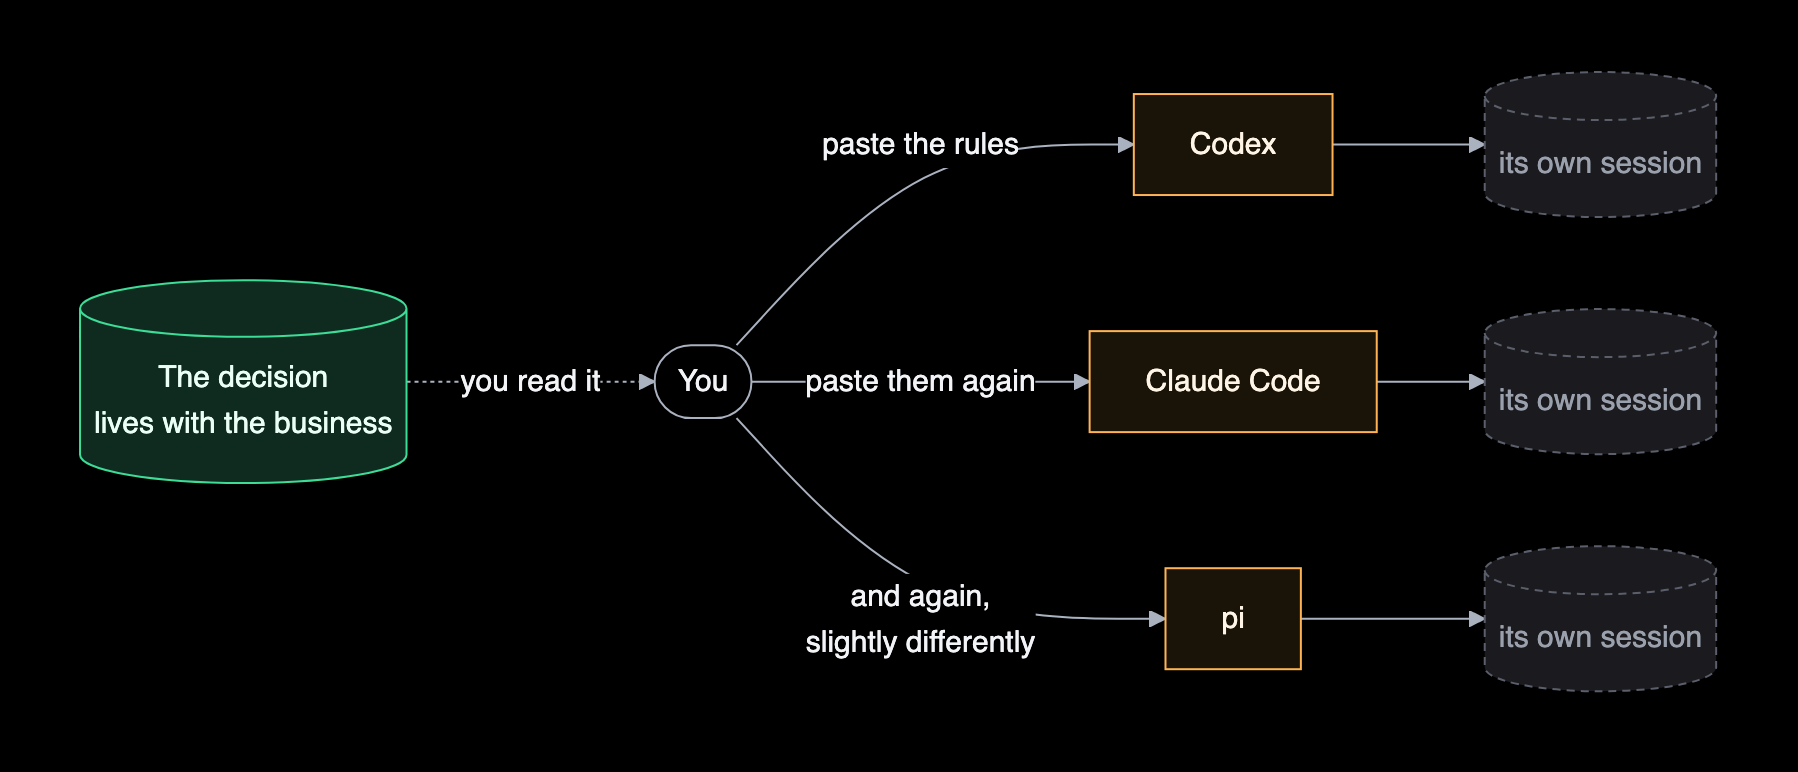

**How to read it.** The decision exists; you can read it. But the only
way it reaches each harness is through you, three times, in three pastes.
The day the sale is extended you get to do it again — and the harness you
forget ships the old date.

## The fixes people reach for first

- **Write it into each harness's memory file.** `AGENTS.md` for one,
  `CLAUDE.md` for another, a third file for the third. Three copies of a
  business decision, in a repository, maintained by whoever remembers.
- **Paste it into every task.** Correct on the day. It doesn't survive the
  first change, and the task gets longer every week.
- **Standardise on one harness.** It solves the copies and costs you the
  reason you had three: they are good at different things, and next
  quarter's best one hasn't shipped yet.

All three try to move the decision *into* the harness. The alternative is
the one from Notebook 1: leave the decision where it is, and let the
harness come to it.

> You don't have to teach every agent what the business decided. You have
> to give every agent the same place to look.

## ⭐ Six terms, defined once

- **An agent harness is the loop around a model that lets it act**: read
  files, run commands, call tools, decide when it's done. Codex, Claude
  Code and pi are harnesses. You run them; you didn't write them.
- **A meta-harness is one interface over many harnesses.** MemoRizz's
  `MetaHarness` takes a task in one shape, runs it on whichever harness
  you name, and applies the same permissions, approvals and record-keeping
  to all of them.
- **A harness task is the unit of work**: what to do, in which folder, on
  which harness, in which memory ID, with which permissions.
- **Starting context is what MemoRizz retrieves from the memory for a task
  and hands to the harness before it begins.** The harness doesn't have to
  know to ask.
- **A saved answer is what a run concluded, written back to the memory
  when it ends**, labelled with the harness that wrote it.
- **A finding is one fact distilled from saved answers**, quoted from the
  answer it came from. Findings are what a memory *knows*; answers are
  what it was *told*.

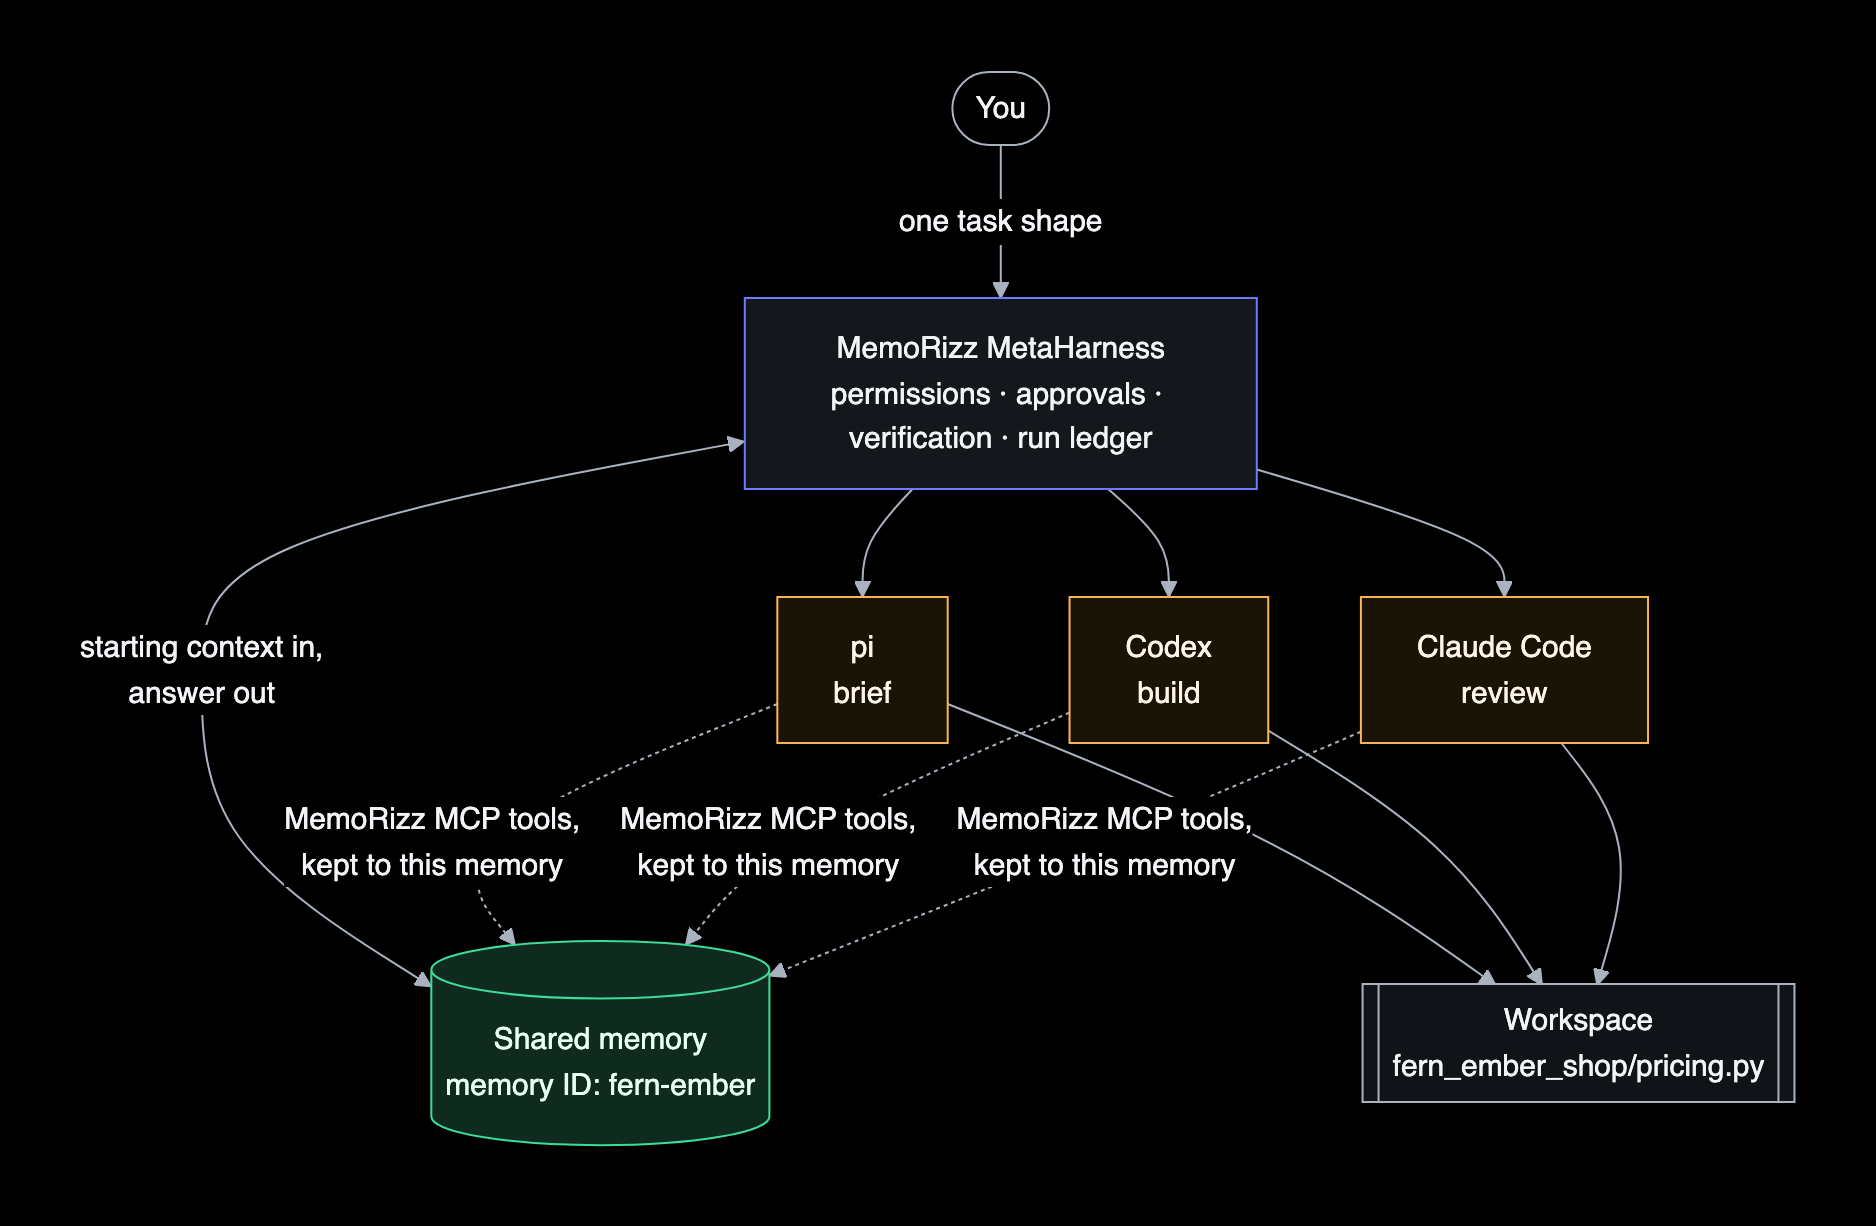

**How to read it.** You talk to one thing. It talks to the memory before
and after every run, and to whichever harness the task names. The
harnesses all work in the same folder. During a run each one can also
search the memory itself through MemoRizz's tools — but it is kept to this
memory ID, and it reads without writing unless you say otherwise.

The shared memory is the same `fern-ember` from Notebook 1. Nothing was
copied, exported or synced to get it here.

# Part 2 · Setup

In this part we open the store Notebook 1 wrote, make a small code
workspace, and start the meta-harness. By the end you'll have three
harnesses ready, and you'll have seen the record they are about to read.

**Before you run it**

- Run **Notebook 1** first. This notebook reads the memory it leaves
  behind (if it hasn't run, a cell below records the decision so you can
  carry on).
- Have at least one of **Codex**, **Claude Code** or **pi** installed and
  signed in. `memorizz harness doctor` tells you which are ready.
- Use **MemoRizz 0.17.27 or later**: sharing a memory between harnesses
  and the refine cycle arrived in that release. Upgrade an older install
  with `pip install -U "memorizz[ui,filesystem]"`.

In [1]:
import importlib.util
import json
import logging
import os
import re
import shutil
import subprocess
import sys
import textwrap
import time
from pathlib import Path

# MemoRizz from PyPI, with the local UI and the file store. Skipped when it is already installed.
if importlib.util.find_spec("memorizz") is None:
    %pip install --quiet "memorizz[ui,filesystem]>=0.17.27"

**The model key.** The harnesses use their own sign-ins. The key is for
the store's embeddings, the refine cycle and Sam.

In [2]:
if not os.getenv("OPENAI_API_KEY"):
    from dotenv import dotenv_values, find_dotenv

    os.environ["OPENAI_API_KEY"] = (
        dotenv_values(find_dotenv(usecwd=True)).get("OPENAI_API_KEY") or ""
    )
assert os.environ["OPENAI_API_KEY"], "Set OPENAI_API_KEY before running this notebook."

**The same store, the same memory ID.** These four lines are the whole
integration between the two notebooks: the folder Notebook 1 wrote to, and
the name of the memory inside it. Note what is *not* here: no `FRESH`, no
wipe. This notebook adds to the shop's memory; it never resets it.

In [3]:
import memorizz
from memorizz import FileSystemConfig, FileSystemProvider, MemoryType

STORE = Path(os.getenv("MEMORIZZ_NB_STORE") or Path.cwd() / "fern_ember_store").resolve()
HOME = STORE.parent / "fern_ember_home"
os.environ["MEMORIZZ_HOME"] = str(HOME)
logging.disable(logging.WARNING)  # keep the lesson's output readable

EMBEDDING = {"model": "text-embedding-3-small", "dimensions": 256}
provider = FileSystemProvider(
    FileSystemConfig(root_path=STORE, embedding_provider="openai", embedding_config=EMBEDDING)
)
LLM = {"provider": "openai", "model": os.getenv("MEMORIZZ_NB_CHAT_MODEL", "gpt-6-luna")}
TEAM = "fern-ember"  # the memory ID from Notebook 1
print("memorizz", memorizz.__version__, "| store:", STORE.name, "| memory:", TEAM)

memorizz 0.17.27 | store: fern_ember_store | memory: fern-ember


**Two helpers from Notebook 1**, unchanged, so answers print the same way
and are graded the same way.

| Name | What it does |
|---|---|
| `say(who, text)` | Prints an answer, wrapped, with a name in front. File links a harness writes are shown from this folder (`local`) |
| `knows(text)` | Returns which facts of the offer a text carries: the dates (3 to 12 March), the 20% and the 10%. A plain string check, not a model |

In [4]:
def local(text):
    """File links a harness writes, shown from this folder."""
    return str(text).replace(str(Path.cwd()) + "/", "")


def say(who, text, limit=900):
    text = local(text)
    text = text if len(text) <= limit else text[:limit].rsplit(" ", 1)[0] + " …"
    print(textwrap.fill(f"{who}: {text}", width=100, subsequent_indent="    "), end="\n\n")


def knows(text, last_day="12"):
    """Which facts of the offer a text carries."""
    words = re.findall(r"[a-z0-9]+", text.lower())
    dates = "3" in words and last_day in words and "march" in words
    facts = (("dates", dates), ("20%", "20%" in text), ("10%", "10%" in text))
    return [fact for fact, present in facts if present]

## ⭐ The record the harnesses will read

Before any harness runs, look at what is already in the memory. This is
the entity record Mara wrote in Notebook 1 — including the end date she
changed on Wednesday.

| Name | Kind | What it does |
|---|---|---|
| `provider.list_all(MemoryType.ENTITY_MEMORY)` | MemoRizz API | Every entity record in the store |
| `team_records()` | Notebook helper | Keeps the ones filed under `fern-ember` |

In [5]:
def team_records(memory_id=TEAM):
    rows = provider.list_all(MemoryType.ENTITY_MEMORY) or []
    return [row for row in rows if row.get("memory_id") == memory_id]


def show_records(memory_id=TEAM):
    for record in team_records(memory_id):
        print(record["name"])
        for attribute in record.get("attributes") or []:
            print(f"   {attribute['name']:<24} {attribute['value']}")

**If Notebook 1 hasn't run here**, the next cell stands in for it: a
one-line Mara records the decision. If it has, the cell only prints.

In [6]:
from memorizz import MemAgentBuilder

if not team_records():
    builder = MemAgentBuilder().with_name("Mara").with_llm_config(LLM)
    builder = builder.with_instruction("You are Mara, the merchandiser. Record decisions in entity memory.")
    builder = builder.with_memory_provider(provider).with_memory_ids([TEAM])
    mara = builder.with_entity_memory(True).with_sandbox(None).build_and_save()
    mara.run(
        "Decision: the Spring Sale runs 3 to 12 March 2027. 20% off all houseplants, "
        "10% off pots, gift cards excluded. Record it.",
        memory_id=TEAM,
    )
show_records()

Spring Sale
   dates                    3–12 March 2027
   discounts                20% off all houseplants; 10% off pots
   exclusions               Gift cards excluded


That record is the brief. Nobody in this notebook will type those dates
into a task.

## The workspace: the shop's code

A harness works in a folder. Ours is deliberately tiny: one file, one
function, one `TODO`. It is a Git repository because MemoRizz fingerprints
the workspace before and after a run, and refuses to edit a folder with
uncommitted changes it didn't make.

Unlike the memory, **the workspace is reset on every run of this
notebook**. Code is cheap to recreate. What the shop knows isn't.

In [7]:
SHOP = STORE.parent / "fern_ember_shop"
STUB = '''# Fern & Ember prices.


def sale_price(price, category, on):
    # The price of one item of a category ('houseplant', 'pot', 'gift card') on a date.
    return price  # TODO: the Spring Sale
'''

shutil.rmtree(SHOP, ignore_errors=True)
SHOP.mkdir()
(SHOP / "pricing.py").write_text(STUB)
git = "git init -q && git add -A && git -c user.name=shop -c user.email=shop@example.com commit -qm start"
subprocess.run(git, shell=True, cwd=SHOP, check=True)
print((SHOP / "pricing.py").read_text())

# Fern & Ember prices.


def sale_price(price, category, on):
    # The price of one item of a category ('houseplant', 'pot', 'gift card') on a date.
    return price  # TODO: the Spring Sale



## ⭐ The meta-harness

One object stands between this notebook and every harness.

| Name | Kind | What it does | Why it matters here |
|---|---|---|---|
| `MetaHarness.from_env(...)` | MemoRizz API | Finds the harnesses installed on this machine and wraps each in the same interface | You never call `codex` or `claude` yourself |
| `memory_provider=provider` | Argument | The store runs read from and save to | **The same provider as the agents in Notebook 1.** Sharing starts here, again |
| `allowed_workspace_roots=[...]` | Argument | The only folders a run may work in | A harness asked to work anywhere else is refused before it starts |
| `.list_harnesses()` | MemoRizz API | Each harness with whether it is installed and signed in | Readiness is checked, not assumed |

In [8]:
from memorizz import MetaHarness

meta = MetaHarness.from_env(memory_provider=provider, allowed_workspace_roots=[str(SHOP)])

ready = []
for harness in meta.list_harnesses():
    if harness["name"] in ("pi", "codex", "claude-code"):
        state = "ready" if harness["ready"] else "not ready"
        print(f"{harness['name']:<12} {state:<10} {harness.get('version') or ''}")
        ready += [harness["name"]] if harness["ready"] else []

claude-code  ready      2.1.332 (Claude Code)
codex        ready      codex-cli 0.164.0
pi           ready      0.99.1


**Three jobs, three harnesses.** Each job names the harness it would like
and settles for the next one that's ready, so the notebook runs on a
machine with only one of them installed. (With one harness you still get
the lesson about memory. You lose the point about vendors.)

In [9]:
def pick(*wanted):
    return next(name for name in wanted if name in ready)


BRIEF = pick("pi", "claude-code", "codex")
BUILD = pick("codex", "claude-code", "pi")
REVIEW = pick("claude-code", "codex", "pi")
print("brief:", BRIEF, "| build:", BUILD, "| review:", REVIEW)

brief: pi | build: codex | review: claude-code


**Housekeeping: forget this notebook's earlier runs.** The memory is kept
between runs, which is the point of it. But a second run of *this*
notebook would find the first run's answers, and the "before" in Part 3
would no longer be a before. So we remove what earlier harness runs left
— their ledger entries, their saved answers, their findings — and nothing
the agents wrote. It teaches nothing about memory; skip it on a first
read.

In [10]:
def forget_harness_work(memory_id=TEAM):
    runs = [r["run_id"] for r in meta.list_runs(limit=200) if r["task"].get("workspace") == str(SHOP)]
    meta.delete_runs(runs)
    for answer in meta.memory_refine.answers(memory_id):
        provider.delete_by_id(answer["id"], MemoryType.CONVERSATION_MEMORY)
    for finding in meta.memory_refine.findings(memory_id, include_replaced=True):
        provider.delete_by_id(finding["id"], MemoryType.KNOWLEDGE_BASE)
    return len(runs)


print("earlier harness runs forgotten:", forget_harness_work())

earlier harness runs forgotten: 5


**Two more helpers, used by every run below.**

| Name | What it does |
|---|---|
| `run_on(harness, task, memory_id=TEAM, **more)` | Runs one task on one harness in the shop's workspace and prints a one-line receipt. `memory_id` is the only thing that decides what the harness can know |
| `given(result)` | Lists the starting context: the records MemoRizz retrieved and handed over before the harness began |

In [11]:
def run_on(harness, task, memory_id=TEAM, **more):
    spec = {"task": task, "workspace": str(SHOP), "harness": harness, "memory_id": memory_id}
    started = time.perf_counter()
    result = meta.run({**spec, **more})
    receipt = f"{harness}: {result.status.value} in {time.perf_counter() - started:.0f}s"
    if result.context_pack:
        receipt += f", handed {len(result.context_pack.records)} records from memory"
    print(receipt, end="\n\n")
    return result


def given(result):
    for record in result.context_pack.records:
        text = " ".join(local(record.get("name") or record.get("content") or "").split())
        print(f"  {record['memory_type']:<20} {text[:76]}")

# Part 3 · A harness with no memory

This part is the baseline. We ask a harness for the sale's rules with
nothing to go on, and grade the answer. By the end you'll have a number to
beat.

The task is the first job: the brief. It is read-only — the harness may
look at the code and may not change it. And it is run with
`memory_id=None`: a run with no memory ID is handed nothing.

We tell it not to guess, for the same reason Cole and Sam were told not to
invent an offer. An honest "I don't know" is the good outcome here.

In [12]:
BRIEF_TASK = (
    "Read pricing.py. List the exact Spring Sale rules sale_price() must implement: "
    "the dates, the discount for each category, and the exclusions. Do not edit files. "
    "If you don't know a rule, say so rather than guess. At most eight lines."
)

alone = run_on(BRIEF, BRIEF_TASK, memory_id=None)
say(BRIEF, alone.final_response)
print("facts:", knows(alone.final_response))

pi: succeeded in 5s, handed 0 records from memory

pi: I read `pricing.py`. It doesn't define any Spring Sale rules. `sale_price(price, category, on)`
    is a stub that returns `price` unchanged, with the comment `# TODO: the Spring Sale`.  -
    **Dates:** Unknown. The file gives no start or end dates. - **Discounts:** Unknown. The file
    names three categories, `houseplant`, `pot` and `gift card`, but gives no discount for any of
    them. - **Exclusions:** Unknown. The file doesn't say which items or categories are excluded. A
    gift card exclusion is plausible, but I'm not assuming it.  I didn't search other files for the
    rules. I made no edits.

facts: []


It read the file, found a `TODO`, and stopped. That is a capable agent
behaving well. It is also no use to anyone: the next step would be you,
pasting the rules.

Notice what is missing from the receipt: **handed 0 records from memory**.
The store is right there, with the record in it. The harness simply wasn't
in a memory.

# Part 4 · Run 1 · The brief

In this part we run the same task, on the same harness, with one argument
changed. By the end you'll have a brief that cites the record Mara wrote
— and you'll have seen exactly what the harness was handed.

Here is the whole notebook in one picture. We're at steps 1 to 6.

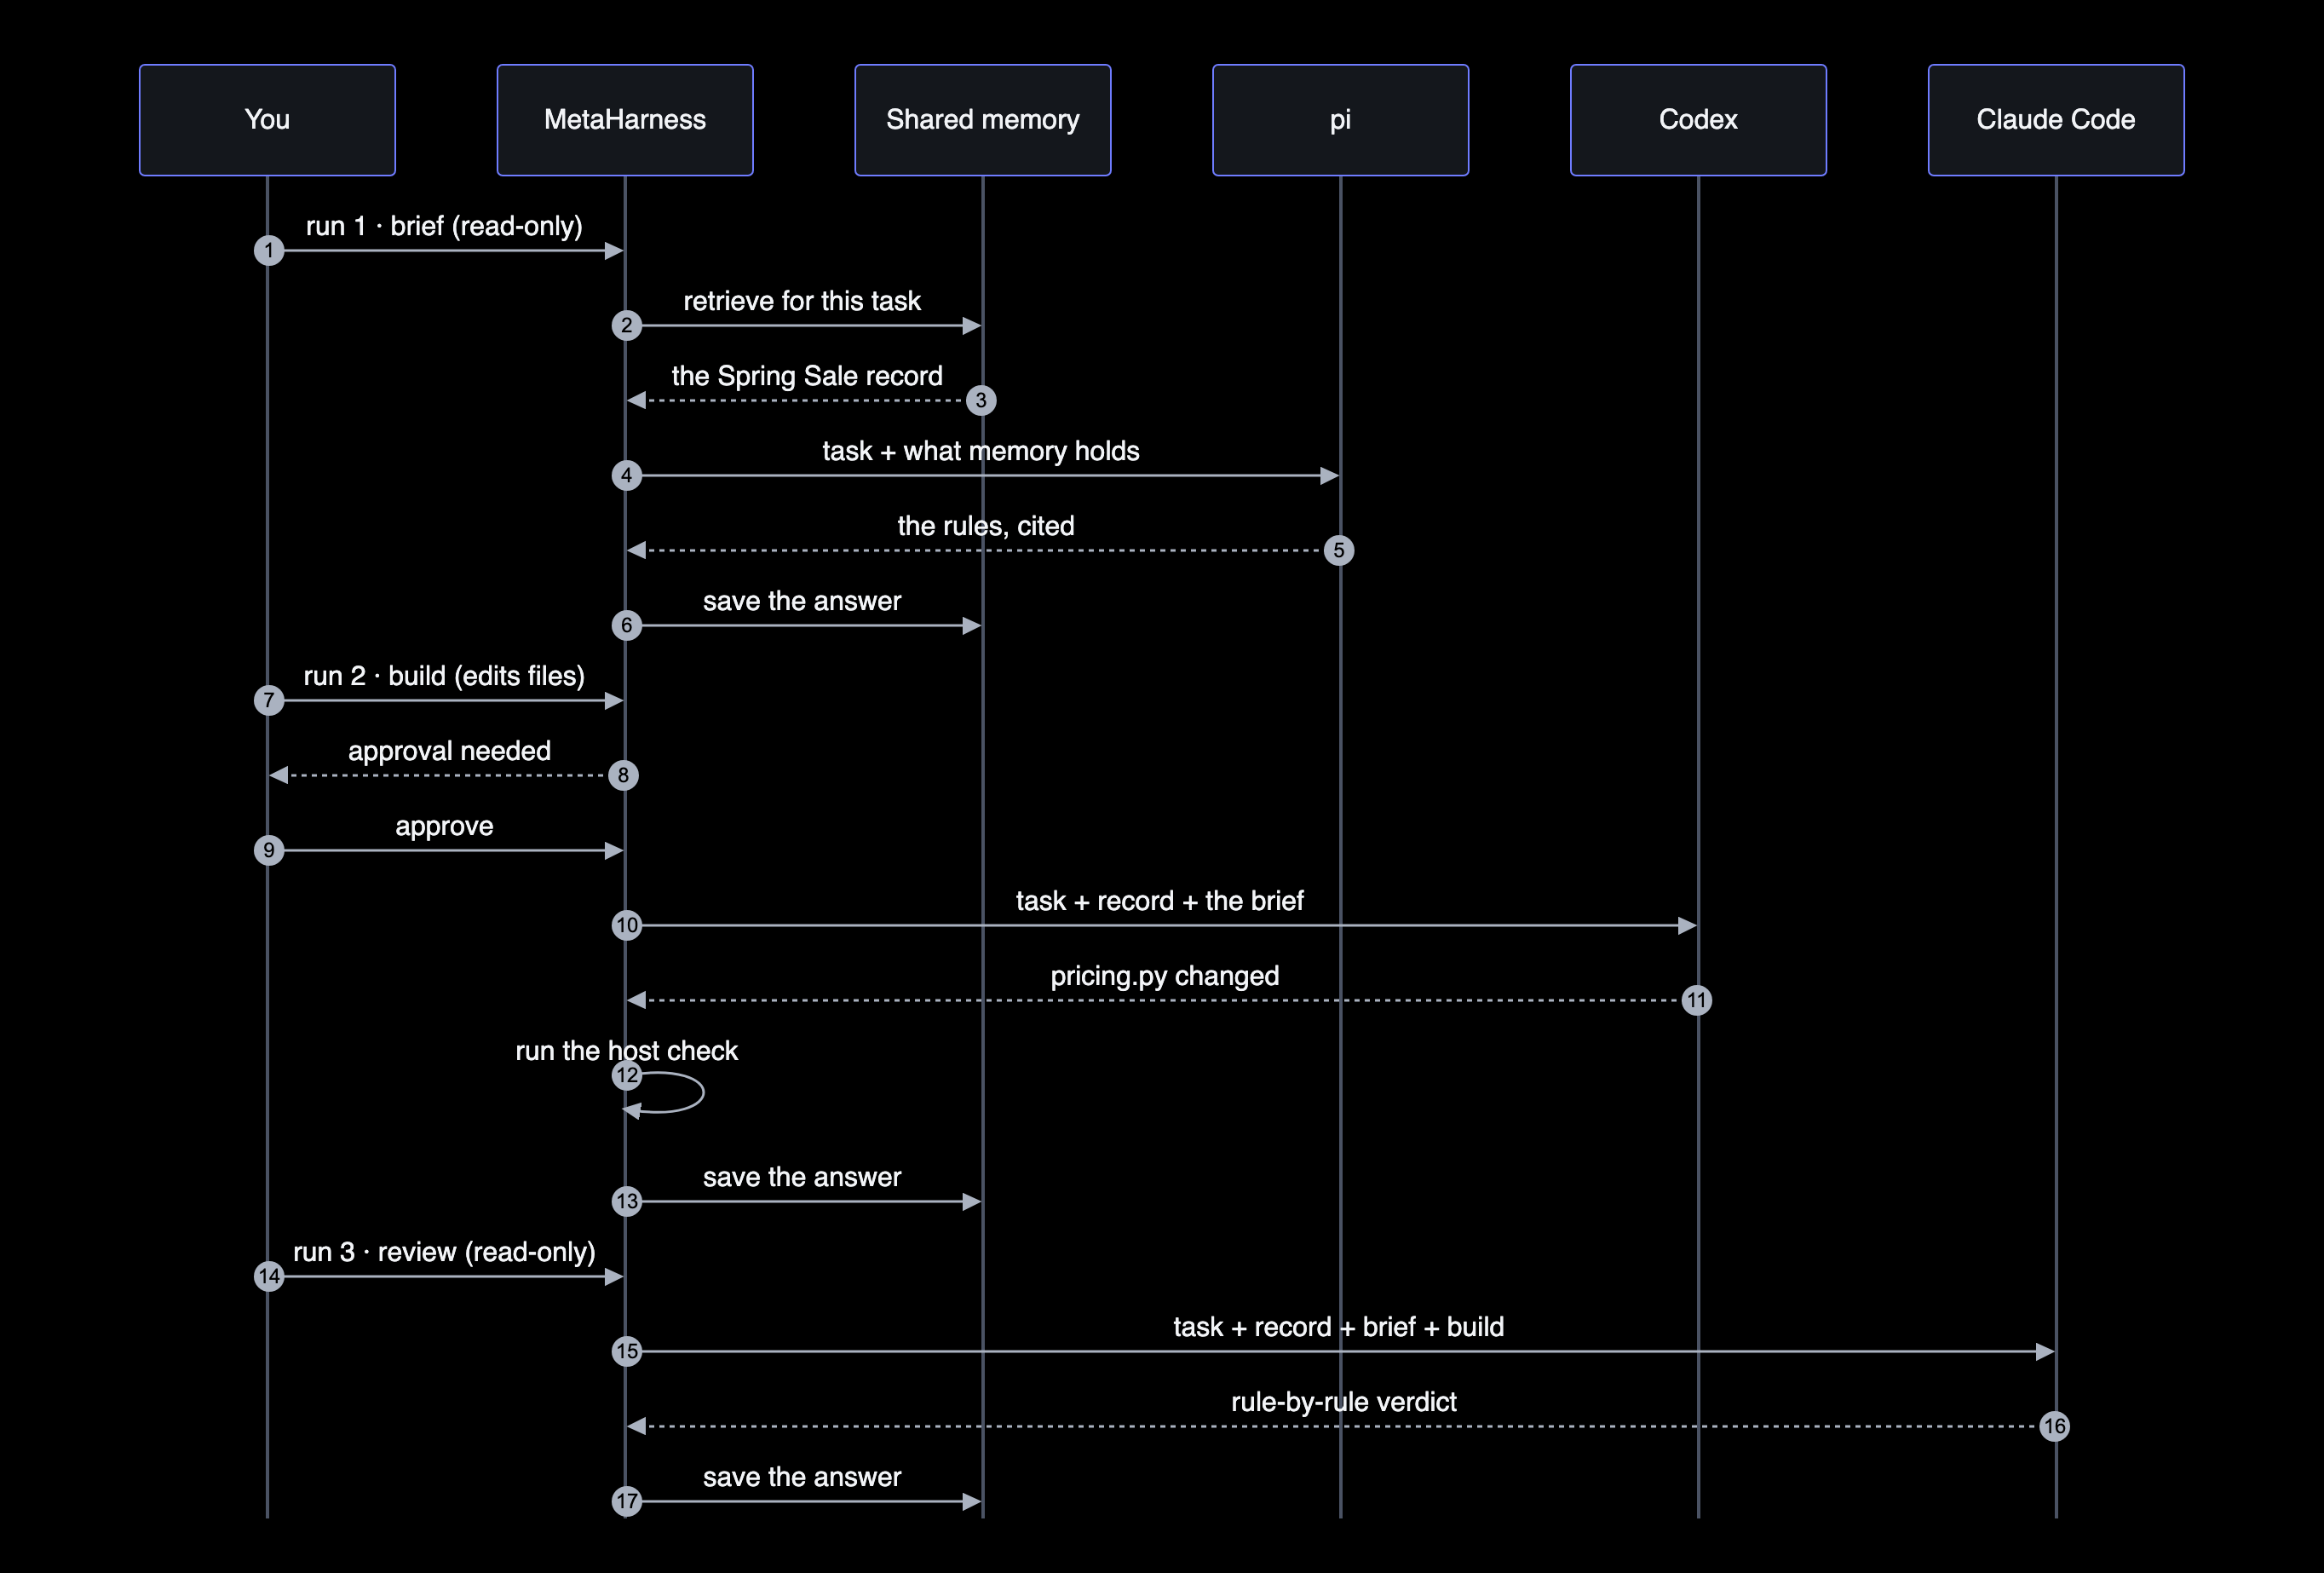

**How to read it.** Every run has the same shape: MemoRizz retrieves from
the memory, the harness works, MemoRizz saves the answer. What changes is
what the memory holds each time. Run 1 finds Mara's record. Run 2 finds
the record *and* the brief. Run 3 finds all of it.

## ⭐ One argument: `memory_id`

In [13]:
brief = run_on(BRIEF, BRIEF_TASK)  # memory_id=TEAM
given(brief)

pi: succeeded in 7s, handed 5 records from memory

  conversation_memory  Marketing would prefer the sale to end on 31 March. Update the Spring Sale r
  conversation_memory  Change of plan: the Spring Sale now ends on 12 March 2027, not 9 March. Upda
  conversation_memory  - **When does it end?** The Spring Sale ends on 12 March 2027. - **Are gift 
  conversation_memory  Updated the Spring Sale record: it now runs **3–12 March 2027**. Discounts a
  entity_memory        Spring Sale


**That list is the starting context.** Nobody wrote a prompt that mentions
March. MemoRizz searched `fern-ember` for records that match the task and
put them in front of the harness: the Spring Sale entity, and turns from
Notebook 1 in which the sale was decided, changed and argued about. Each
arrives with its source ID, so the harness can cite it.

In [14]:
say(BRIEF, brief.final_response)
print("facts:", knows(brief.final_response))

pi: pricing.py has no Spring Sale rules. `sale_price()` is a stub that returns `price` unchanged.
    The rules below come only from memory.  - **Dates:** 3–12 March 2027 inclusive, per the Spring
    Sale entity record [memory:entity_memory:6b7de279-1207-5689-bfba-73a40828256a]. The end date was
    moved from 9 March to 12 March
    [memory:conversation_memory:ca9940bd-f75a-4a9d-9ccd-039e47cac241]. - **Houseplants:** 20% off. -
    **Pots:** 10% off. - **Gift cards:** excluded, so no discount. - **Unconfirmed:** A request in
    thread cole-tries asked for the sale to end on 31 March
    [memory:conversation_memory:fb92a94e-9aa0-4d6b-a62c-41a4e5cdf42a]. The entity record doesn't
    show it applied, so I can't say whether it is approved. - **Unknown:** I don't know the rounding
    rules. I also don't know whether the start and end dates are inclusive. "3–12 March" suggests
    they are, but that is my assumption.

facts: ['dates', '20%', '10%']


Same harness, same task, same code. From "I don't know" to the full offer
— including the end date Mara *changed*, because the record is the current
value and the harness was handed the record.

Look for the `memory:` references in the answer. They aren't decoration: a
brief that says where each rule came from is a brief you can check. It may
also mention Marketing's request to end on 31 March, which Cole declined
to record in Notebook 1. A shared memory hands over the argument as well
as the decision; a good brief tells them apart.

When the run ended, MemoRizz saved this answer to `fern-ember`. The next
run will find it.

# Part 5 · Run 2 · The build

In this part a different harness changes the code. You'll see the two
things a meta-harness puts around an edit — an approval before, a check
after — and by the end `sale_price()` will be implemented and verified.

## ⭐ The check comes first

An agent that edits code will tell you it worked. Sometimes it's right.
So before the build we write down, as code, what "worked" means.

The check lives **outside the workspace**, beside the notebook's settings.
The harness being checked can read and edit `fern_ember_shop`; it can't
reach this file. The five cases were written by a person who read the
record, not by the agent that is about to be graded.

In [15]:
CHECK = HOME / "check_pricing.py"
CASES = [
    (40, "houseplant", (2027, 3, 5), 32.0),  # in the sale: 20% off
    (20, "pot", (2027, 3, 12), 18.0),  # the last day counts: 10% off
    (50, "gift card", (2027, 3, 5), 50.0),  # never discounted
    (40, "houseplant", (2027, 3, 13), 40.0),  # the day after
    (40, "houseplant", (2027, 3, 2), 40.0),  # the day before
]
CHECK.write_text(textwrap.dedent(f'''
    import sys
    from datetime import date
    sys.path.insert(0, ".")
    from pricing import sale_price
    wrong = [c for c in {CASES!r} if abs(sale_price(c[0], c[1], date(*c[2])) - c[3]) > 0.005]
    print("checked {len(CASES)} prices;", len(wrong), "wrong", wrong)
    sys.exit(1 if wrong else 0)
'''))
print(CHECK.name, "is in", CHECK.parent.name, "| the harness works in", SHOP.name)

check_pricing.py is in fern_ember_home | the harness works in fern_ember_shop


## ⭐ A run that edits stops and asks

The build task differs from the brief in two fields.

| Field | Value | What it means |
|---|---|---|
| `permissions.workspace_mode` | `"direct"` | The harness may edit files in the workspace. The default is `"read_only"` |
| `verification.command` | The check above | MemoRizz runs it itself after the harness finishes; the run is `verified` only if it exits 0 |

Notice what the task *doesn't* say: no dates, no percentages. It says "the
Spring Sale the team recorded".

In [16]:
BUILD_TASK = (
    "Implement sale_price(price, category, on) in pricing.py so it applies the Spring Sale "
    "the team recorded in memory: the right dates, the right discount for each category, and "
    "the exclusions. `on` is a datetime.date. Keep it small."
)
pending = run_on(
    BUILD,
    BUILD_TASK,
    permissions={"workspace_mode": "direct", "network": "none"},
    verification={"command": f"{sys.executable} {CHECK}"},
)
print("pricing.py still has its TODO:", "TODO" in (SHOP / "pricing.py").read_text())

codex: pending_approval in 0s

pricing.py still has its TODO: True


**Zero seconds, and `pending_approval`.** The harness hasn't started.
MemoRizz recorded a *proposal*: this task, these permissions, this check,
this exact state of the workspace. It will run that and only that, once a
person says so.

`approve()` takes the proposal and the name of who approved it. In a
product this is a button; here it is a line, so you can see there is
nothing else to it.

In [17]:
proposal_id = pending.checkpoint["proposal_id"]
meta.approve(proposal_id, approver_id="you@fern-ember.example", reason="Reviewed the task and the check.")

started = time.perf_counter()
build = meta.resume_approval(proposal_id)
print(f"{BUILD}: {build.status.value} in {time.perf_counter() - started:.0f}s")
say(BUILD, build.final_response)

codex: succeeded in 19s
codex: Implemented the Spring Sale in [pricing.py](fern_ember_shop/pricing.py): 20% off houseplants
    and 10% off pots from 3–12 March 2027, inclusive. Gift cards and other categories remain
    undiscounted. The dates and discounts come from the recorded offer
    [memory:entity_memory:6b7de279-1207-5689-bfba-73a40828256a].  The acceptance check passed: 5
    prices checked, 0 wrong.



If the workspace had changed between the proposal and the approval, the
approval would be void: you approved an edit to *that* code, not to
whatever is there now.

## ⭐ "Done" is a claim. This is the fact

Two things to look at, neither of them the harness's own account: the
result of the check MemoRizz ran, and the diff.

In [18]:
check = build.verification
print("verified:", build.verified, "|", check["stdout"].strip(), "| exit code", check["return_code"])
print()
print(subprocess.run(["git", "diff", "--unified=0"], cwd=SHOP, capture_output=True, text=True).stdout)

verified: True | checked 5 prices; 0 wrong [] | exit code 0

diff --git a/pricing.py b/pricing.py
index a621abe..6d122d0 100644
--- a/pricing.py
+++ b/pricing.py
@@ -2,0 +3,2 @@
+from datetime import date
+
@@ -6 +8,4 @@ def sale_price(price, category, on):
-    return price  # TODO: the Spring Sale
+    if date(2027, 3, 3) <= on <= date(2027, 3, 12):
+        discount = {'houseplant': 20, 'pot': 10}.get(category, 0)
+        return price - price * discount / 100
+    return price



Read the dates in that diff. **Nobody typed them.** Not in the task, not
in a prompt, not in a config file. Mara said them to an agent in Notebook
1; a coding harness from a different vendor has just written them into a
Python file, and a check written by a third party agrees.

That is one decision, travelling from a conversation to a codebase through
nothing but a memory ID.

# Part 6 · Run 3 · The review

In this part a third harness reviews the change. By the end you'll have a
rule-by-rule verdict — and you'll see that the reviewer was handed the
other two harnesses' work without being told they exist.

The task is read-only again, so it runs straight away. Look at what it's
given this time.

In [19]:
REVIEW_TASK = (
    "Review the Spring Sale implementation in pricing.py against the rules in the team's "
    "memory and against what the build reported. Say whether each rule (the dates, each "
    "discount, the exclusions) is implemented correctly. The build's check is run by the host "
    "on this folder and is not yours to review. Do not edit files. At most eight lines."
)
review = run_on(REVIEW, REVIEW_TASK)
given(review)

claude-code: succeeded in 10s, handed 6 records from memory

  conversation_memory  [Harness run: codex · succeeded] Implemented the Spring Sale in [pricing.py]
  conversation_memory  [Harness run: pi · succeeded] pricing.py has no Spring Sale rules. `sale_pri
  conversation_memory  Check the team's offer records and confirm the Spring Sale offer in one line
  conversation_memory  Prepare the Spring Sale launch pack. Mara: confirm the offer in one line. Co
  entity_memory        Spring Sale
  knowledge_base       codex changed pricing.py and its check passed. Asked: Implement sale_price(p


**The lines that begin `[Harness run: …]` are the point of this
notebook.** They are what the earlier harnesses concluded, saved by
MemoRizz when those runs ended and retrieved now because they match the
task. The reviewer starts with the decision and with its colleagues'
account of the work.

Three harnesses from three vendors have no way to talk to each other. They
don't need one.

In [20]:
say(REVIEW, review.final_response)

claude-code: All three rules in `pricing.py` match the Spring Sale record in memory
    [memory:entity_memory:6b7de279-1207-5689-bfba-73a40828256a].  - **Dates: correct.**
    `pricing.py:8` applies the sale from 3 to 12 March 2027, start and end days included. That uses
    the updated end date of 12 March, not the earlier 9 March. A separate request to end it on 31
    March was never applied to the record
    [memory:conversation_memory:fb92a94e-9aa0-4d6b-a62c-41a4e5cdf42a], so 12 March is right. -
    **Houseplants, 20% off: correct** (`pricing.py:9`). - **Pots, 10% off: correct**
    (`pricing.py:9`). - **Gift cards excluded: correct.** Any category not listed gets no discount,
    so gift cards stay at full price. - **Rounding:** prices aren't rounded to pennies, and memory
    has no rounding rule to check this against. - **Build report:** the code matches what it
    claimed. However, the check it reported passing was run from …



A review against the *memory*, not against the reviewer's guess at what
the code is for. If it flags something — a rule satisfied only by
default, say — that observation is now in the memory too, for whoever
touches this file next.

# Part 7 · What the memory holds now

In this part we stop running things and look. By the end you'll have seen
the two places a harness run leaves a trace: the memory, and the ledger.

## ⭐ The memory: three answers, three authors

| Name | Kind | What it does |
|---|---|---|
| `meta.memory_refine.answers(memory_id)` | MemoRizz API | The answers harness runs saved to this memory, oldest first, each with the harness that wrote it |

In [21]:
for answer in meta.memory_refine.answers(TEAM):
    first_line = " ".join(local(answer["text"]).split())[:84]
    print(f"{answer['harness']:<12} {first_line}")

pi           pricing.py has no Spring Sale rules. `sale_price()` is a stub that returns `price` u
codex        Implemented the Spring Sale in [pricing.py](fern_ember_shop/pricing.py): 20% off hou
claude-code  All three rules in `pricing.py` match the Spring Sale record in memory [memory:entit


These are rows in the same conversation memory, under the same memory ID,
as Mara's and Cole's turns from Notebook 1. The baseline run from Part 3
isn't among them: it ran in no memory, so it left nothing in one.

## One fact, kept without being asked

An answer is what a harness *said*. Two things about the build weren't
said by anyone: MemoRizz watched which file changed, and ran the check
itself. It keeps that as a **finding** the moment the run ends — no model,
no waiting — so the rest of the team can rely on it straight away.

In [22]:
for finding in meta.memory_refine.findings(TEAM):
    print(textwrap.fill(finding["text"], width=100, subsequent_indent="  "))
    print("  from:", finding["quote"], "|", ", ".join(finding["harnesses"]))

codex changed pricing.py and its check passed. Asked: Implement sale_price(price, category, on) in
  pricing.py so it applies the Spring Sale the team recorded in memory: the right dates, the right
  discount for each category, and the exclusions. `on` is a datetime.date. Keep it small.
  from: Files changed: pricing.py | codex


"Changed `pricing.py`, and its check passed." Nobody had to claim it.

## The ledger: what ran, with what rights

The memory keeps what was *learned*. The run ledger keeps what was *done*:
every run, on every harness, with its status, its permissions and whether
its check passed. It lives beside the store and survives restarts.

In [23]:
for run in reversed(meta.list_runs(limit=10)):
    task = run["task"]
    mode = task["permissions"]["workspace_mode"]
    verified = (run.get("result") or {}).get("verified")
    memory = task.get("memory_id") or "(none)"
    print(f"{run['harness']:<12} {run['status']:<10} {mode:<10} memory: {memory:<11} verified: {verified}")

pi           succeeded  read_only  memory: (none)      verified: False
pi           succeeded  read_only  memory: fern-ember  verified: False
codex        succeeded  direct     memory: fern-ember  verified: True
claude-code  succeeded  read_only  memory: fern-ember  verified: False


Four runs. One had no memory and learned nothing it could keep. One edited
files, and it is the only one marked `direct` and the only one with a
check to pass. If someone asks next month who changed the pricing and who
said they could, this is where the answer is.

# Part 8 · From answers to findings

In this part we tidy up. Three runs left three long answers; by the end
the memory will hold a handful of short, quoted facts instead — and you'll
know why that matters more with every run.

## Why raw answers aren't enough

A saved answer is a harness's whole reply: headings, hedges, file paths,
a paragraph about what it didn't check. Hand the next run ten of those and
it spends its attention re-reading its colleagues. Retrieval gets vaguer
as the pile grows. Death by a thousand transcripts.

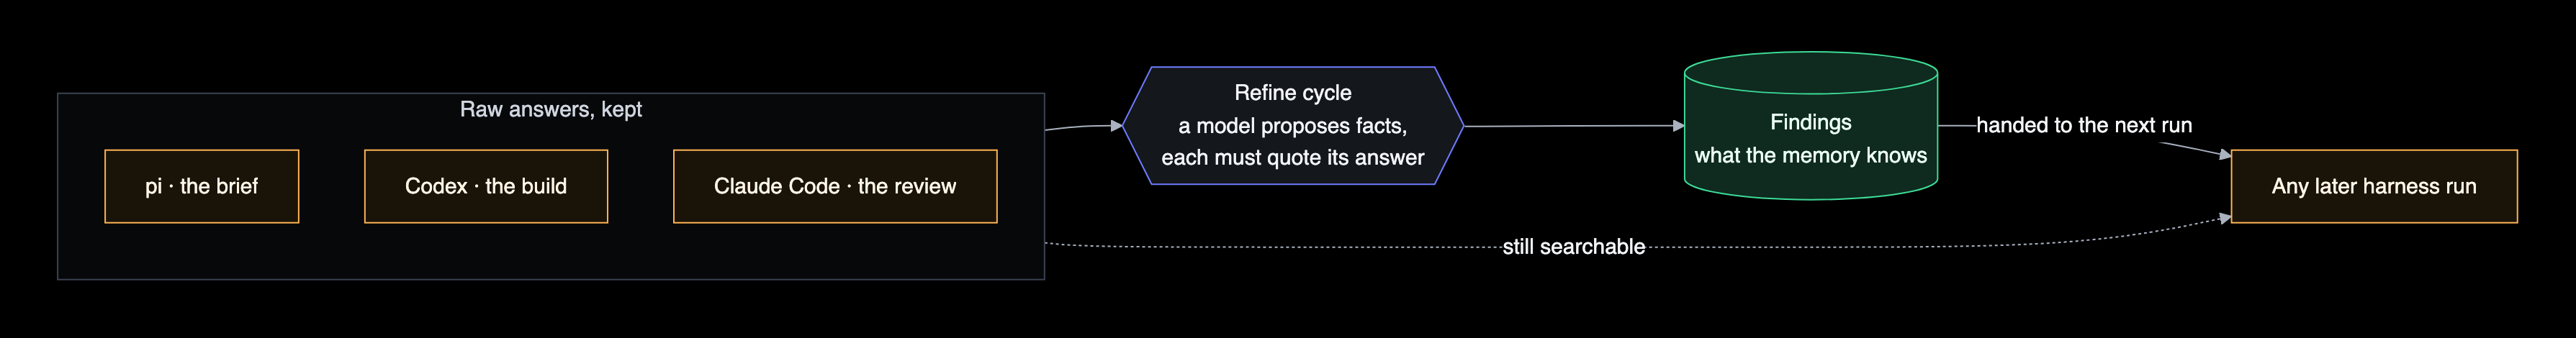

**How to read it.** A model reads the new answers and proposes facts. Each
fact has to quote the answer it came from, or it is dropped. A fact two
runs agree on is confirmed, not duplicated. A fact a later run corrects is
replaced. The raw answers are kept, marked as distilled; later runs are
handed the findings in their place.

| Name | Kind | What it does |
|---|---|---|
| `meta.refine_memory(memory_id, model=...)` | MemoRizz API | Runs one refine cycle over the memory's new answers and returns a report |
| `model=LLM` | Argument | The model that proposes findings. A small, cheap one is the right choice |

In [24]:
report = meta.refine_memory(TEAM, model=LLM)
print("refine:", report["status"], "|", report["changed"], "changes")

for finding in meta.memory_refine.findings(TEAM):
    who = ", ".join(finding["harnesses"])
    print(textwrap.fill(f"- {finding['text']}  [{who}]", width=100, subsequent_indent="  "))

refine: done | 9 changes
- codex changed pricing.py and its check passed. Asked: Implement sale_price(price, category, on) in
  pricing.py so it applies the Spring Sale the team recorded in memory: the right dates, the right
  discount for each category, and the exclusions. `on` is a datetime.date. Keep it small.  [codex]
- The Spring Sale runs from 3 through 12 March 2027, inclusive.  [claude-code]
- During the Spring Sale, houseplants receive 20% off.  [claude-code]
- Gift cards and any other category not listed for a discount remain at full price.  [claude-code]
- The reported acceptance check for the fern_ember_shop pricing change was run from the
  fern_ember_home folder, not the shop folder.  [claude-code]
- The current sale implementation does not round prices to pennies, and memory has no rounding rule
  for it.  [claude-code]


Each finding carries the harnesses whose answers support it, and (in the
record) the sentence it was quoted from. The one MemoRizz recorded by
itself in Part 7 is still there, now among what the model distilled from
the three answers. This is the harness-side cousin
of the entity record from Notebook 1: a fact as a row, not a fact buried
in a transcript.

You can run the cycle by hand like this, on a schedule, or let MemoRizz
start one whenever enough new answers have piled up.

# Part 9 · Back to the team

This is the part the notebook has been walking towards. A customer writes
to support. By the end you'll have seen a MemAgent answer from work a
coding harness did — with no integration between them at all.

**Sam** is the support agent from Notebook 1. He has never heard of Codex.
He runs in `fern-ember`, and before every answer he retrieves what that
memory holds for the question.

| Name | Kind | What it does |
|---|---|---|
| `provider.list_memagents()` | MemoRizz API | The agents saved in the store |
| `MemAgent.load(agent_id, memory_provider=...)` | MemoRizz API | Loads a saved agent exactly as Notebook 1 left it: instructions, memory, reader's rights |

In [25]:
from memorizz import MemAgent

saved = {agent.name: agent.agent_id for agent in provider.list_memagents()}
sam = MemAgent.load(saved.get("Sam") or saved["Mara"], memory_provider=provider)

QUESTION = (
    "A customer wants to know the Spring Sale discount will be right at checkout. Has "
    "engineering implemented the sale in the shop's pricing code, and did it pass its check?"
)
say(sam.name, sam.run(QUESTION, memory_id=TEAM, thread_id="sam-after-engineering"))

Sam: Engineering has reportedly implemented the Spring Sale pricing, and its check passed. However,
    the acceptance check was run from the `fern_ember_home` folder rather than the shop folder, so
    we can’t confirm the shop’s pricing check passed. I’ll check whether it’s been rerun in the
    correct folder.



Sam has never opened `pricing.py`. He knows the sale is in it, and that it
passed its check, because a harness said so and the refine cycle made a
finding of it — and findings are records in the memory he retrieves from
before every answer.

Notice, too, what a careful agent *won't* say. Nobody recorded that the
code is live on the website, so Sam has no business promising it. A shared
memory makes agents consistent about what the team knows. It also makes
them consistent about what it doesn't.

Follow the fact the whole way round:

1. **Mara** (a MemAgent) recorded the decision. *Notebook 1.*
2. **pi** (a harness) turned it into a brief.
3. **Codex** (another vendor's harness) wrote it into the code.
4. **Claude Code** (a third) checked the code against it.
5. **Sam** (a MemAgent) told a customer.

Five agents of two kinds from four vendors. Nobody sent anybody a
message.

> An integration connects two systems. A shared memory connects however
> many turn up.

# Part 10 · See it in the UI

The store and the run ledger are both on disk, so the MemoRizz console can
show them. In this part we print the command. By the end you can click
through the runs, what each was handed, and the memory they share.

It is the same command as Notebook 1, for the same reason: the same home
(that's where the run ledger is), the same embedding model, the same
folder.

In [26]:
def ui_command(port=8765):
    return (
        f"MEMORIZZ_HOME=$PWD/{HOME.name} "
        "MEMORIZZ_DEFAULT_EMBEDDING_PROVIDER=openai "
        "MEMORIZZ_DEFAULT_EMBEDDING_MODEL=text-embedding-3-small "
        "MEMORIZZ_DEFAULT_EMBEDDING_DIMENSIONS=256 "
        f"memorizz ui --backend filesystem --path $PWD/{STORE.name} --port {port}"
    )


print(ui_command())

MEMORIZZ_HOME=$PWD/fern_ember_home MEMORIZZ_DEFAULT_EMBEDDING_PROVIDER=openai MEMORIZZ_DEFAULT_EMBEDDING_MODEL=text-embedding-3-small MEMORIZZ_DEFAULT_EMBEDDING_DIMENSIONS=256 memorizz ui --backend filesystem --path $PWD/fern_ember_store --port 8765


Run that in a terminal, from this notebook's folder, then look at four
things:

| Where | What you'll see | Which part of the notebook it is |
|---|---|---|
| **Agent harnesses** | The four runs, newest first, each with its harness, status and whether its check passed | Parts 3 to 6 |
| **A run → Memory** | What that run was handed before it started, and what it saved | Parts 4 and 6 |
| **Agent harnesses → the `fern-ember` memory** | The answers the harnesses saved, the findings, and the refine cycle that made them | Parts 7 and 8 |
| **Memory types → Shared → `fern-ember`** | Mara, Cole, Sam and Ona — and now Codex, Claude Code and pi beside them, in the same memory | The whole notebook |

The last one is worth a moment. It's the page from Notebook 1, and it has
three new names on it.

In [27]:
notes = STORE / "notebook_runs.json"
runs = json.loads(notes.read_text()) if notes.exists() else {}
runs["02_harnesses"] = {
    "memory_id": TEAM,
    "workspace": str(SHOP),
    "runs": {"brief": brief.run_id, "build": build.run_id, "review": review.run_id},
    "harnesses": {"brief": BRIEF, "build": BUILD, "review": REVIEW},
}
notes.write_text(json.dumps(runs, indent=2))
meta.close()
print(json.dumps(runs["02_harnesses"]["harnesses"], indent=2))

{
  "brief": "pi",
  "build": "codex",
  "review": "claude-code"
}


# Part 11 · Trade-offs, and what comes next

Shared memory made three briefings unnecessary. Here is what it costs, and
where it is the wrong tool.

## When to put harnesses in a shared memory

| Share it when | Don't when |
|---|---|
| Several harnesses work on the same thing over days | It is a one-off question with nothing worth keeping |
| The rules come from outside the repository: a decision, a customer, a policy | Everything the agent needs is already in the code and its tests |
| You want the reviewer to see what the builder claimed | The harnesses are being compared, and must not see each other's answers |

## What it costs

- **A saved answer can be wrong, and the next run will read it.** A
  harness that confidently misreads the code leaves that misreading in the
  memory. This is the Notebook 1 lesson again — every writer can be wrong
  for everyone — and the defences are the same: verified runs, findings
  that must quote their source, and a refine cycle that lets a later run
  replace an earlier one.
- **Starting context is retrieved, not guaranteed.** MemoRizz hands over
  what *matches the task*. A vague task retrieves vague context. "Apply
  the Spring Sale the team recorded" finds the record; "fix pricing" may
  not.
- **Approval is a speed bump on purpose.** Every editing run waits for a
  person. For a fleet of unattended agents that is the wrong default, and
  you'd grant narrower rights up front instead. For a shop's pricing it is
  exactly right.
- **The memory travels; the sign-ins don't.** Each harness still needs its
  own CLI, its own account and its own bill. A meta-harness gives you one
  interface, not one invoice.
- **Read-only is the default for a reason.** During a run a harness can
  search this memory through MemoRizz's tools, and can't write to it
  unless the task says so. What reaches the memory is the answer MemoRizz
  saves at the end — one row, labelled.

> A harness with a shared memory is a colleague. A harness without one is
> a very fast contractor you have to brief every morning.

## The same three jobs as one plan

We ran the three jobs one at a time so each could be looked at. In
practice you'd hand the meta-harness the whole sequence. Each stage runs
on its own harness, later stages are handed what earlier ones concluded,
and a stage that edits still waits for approval:

```python
workflow = meta.start_plan(
    {"task": "Apply the Spring Sale the team recorded to pricing.py.",
     "workspace": str(SHOP), "memory_id": TEAM,
     "verification": {"command": f"{sys.executable} {CHECK}"}},
    [
        {"name": "brief", "harness": "pi", "workspace_mode": "read_only"},
        {"name": "build", "harness": "codex", "workspace_mode": "direct"},
        {"name": "review", "harness": "claude-code", "workspace_mode": "read_only"},
    ],
)
```

And when you don't know which harness is best for a job,
`meta.start_compare(...)` runs the same task on several, each in its own
copy of the workspace, and judges the results. The shared memory is what
keeps the winner's lesson.

## ⭐ The same memory, three kinds of agent

Two notebooks, one store, one memory ID. In the first, agents you built
shared it. In this one, agents you *didn't* build did.

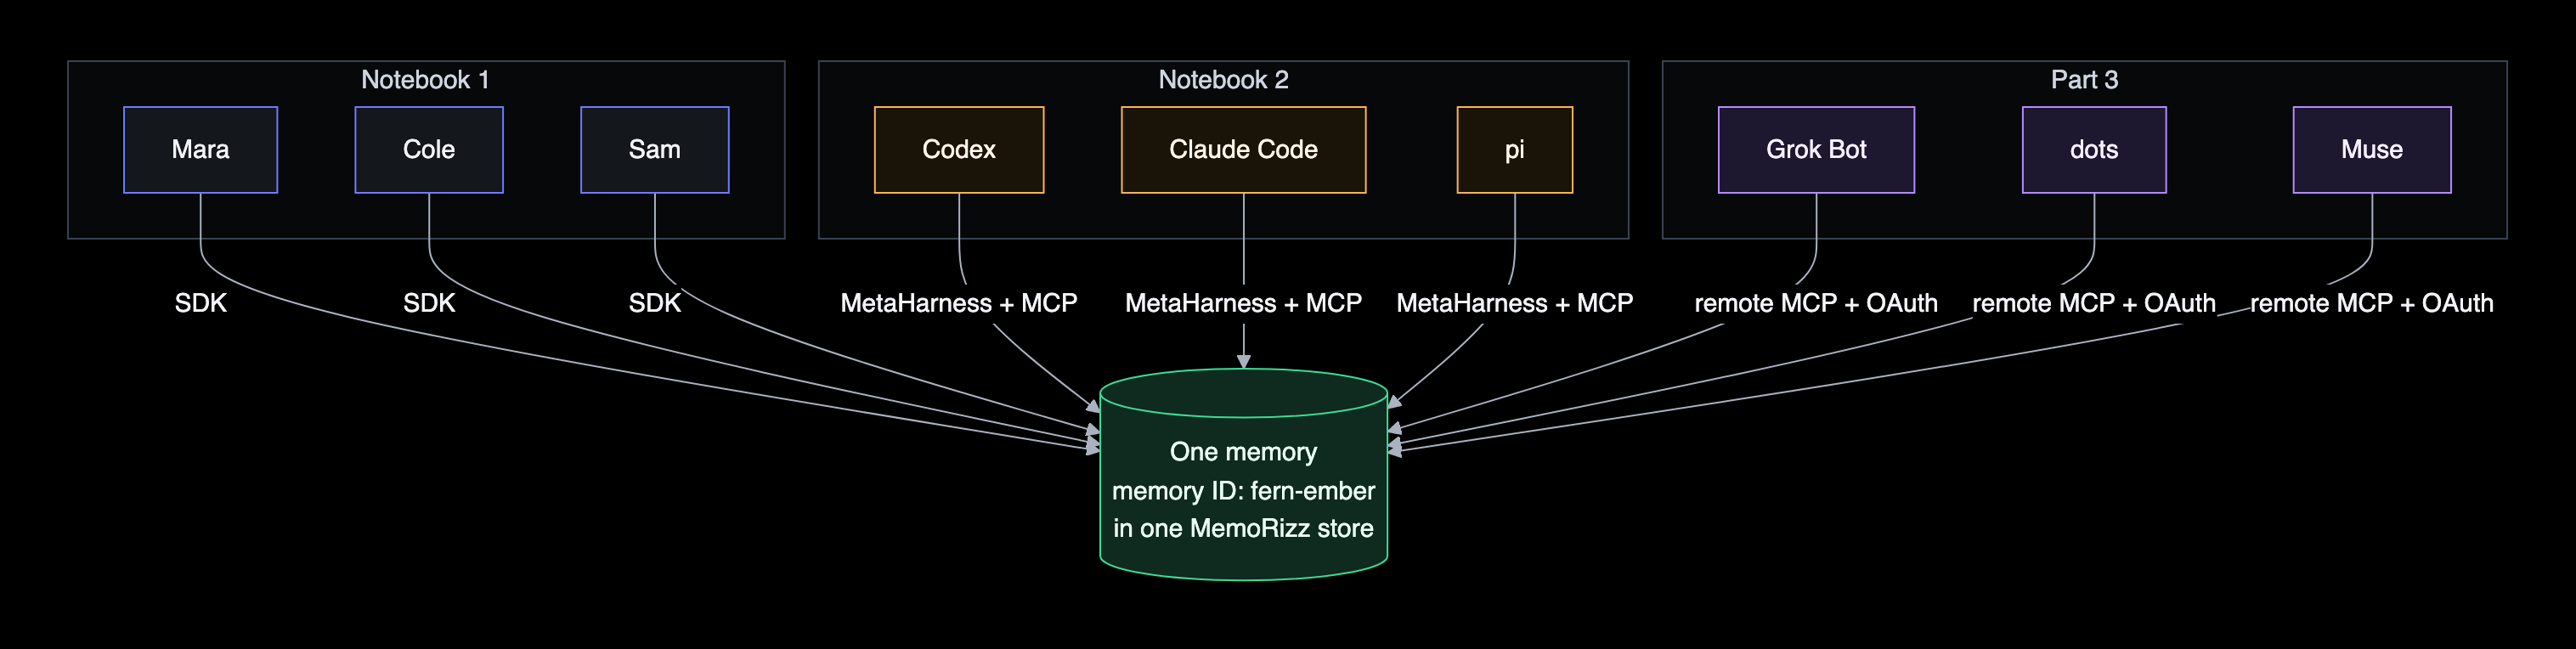

**Part 3** takes the last step: the assistants you carry around. Muse,
Grok Bot and a dot connect to the same store over MCP, so the assistant on
your phone can tell you when the sale ends, whether the code is ready —
and who said so.

The memory doesn't move. The agents come to it.

## FAQ

1. **Does the harness know it is using MemoRizz?** Not in any way that
   matters. The starting context arrives as part of its task, and the
   memory tools appear as ordinary MCP tools. Nothing was installed into
   Codex, Claude Code or pi for this notebook.
2. **What happens to `AGENTS.md` and `CLAUDE.md`?** Keep them. They are
   the right place for how to work in *this repository*: commands,
   conventions, layout. A shared memory is for what isn't the
   repository's to know — decisions, customers, what another agent found
   yesterday.
3. **Can a harness write to the entity record Mara owns?** Not here. Runs
   read the memory and can't write to it; what they conclude is saved as
   an answer, in conversation memory, with their name on it. Mara's record
   changes when Mara changes it. Few writers, many readers.
4. **What if two harnesses disagree?** Both answers are kept. The refine
   cycle confirms what they agree on and, when a later run corrects an
   earlier one, replaces the finding and records why. Disagreement you can
   see is better than a silent overwrite.
5. **What if the decision changes after the code is written?** The record
   changes; the code doesn't. Run the review again and the reviewer is
   handed the new record and the old code, and says so. A shared memory
   doesn't keep code in step by itself. It makes being out of step easy
   to find.
6. **Does this need three harnesses?** No. One harness across many
   sessions has the same problem — each session starts cold — and the
   same fix. Three vendors just make the point harder to miss.
7. **Is the file store safe for this?** For a notebook, yes. For several
   machines or people running harnesses against one memory, use a
   database-backed provider. Shared state is what databases are for.
8. **Can I see all this without the notebook?** Yes: Part 10.